In [1]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [2]:
model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [3]:
optimizer = keras.optimizers.SGD(
    learning_rate=0.01
)

model.compile(
    optimizer=optimizer,
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [4]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5203 - loss: 0.6802 - val_accuracy: 0.5125 - val_loss: 0.6692
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6516 - loss: 0.6384 - val_accuracy: 0.7437 - val_loss: 0.6307
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7891 - loss: 0.6027 - val_accuracy: 0.8125 - val_loss: 0.5971
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8469 - loss: 0.5711 - val_accuracy: 0.8438 - val_loss: 0.5675
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8625 - loss: 0.5429 - val_accuracy: 0.8438 - val_loss: 0.5411
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8609 - loss: 0.5177 - val_accuracy: 0.8375 - val_loss: 0.5179
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8656 - loss: 0.4955 - val_accuracy: 0.8375 - val_loss: 0.4972
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8625 - loss: 0.4757 - val_accuracy: 0.8375 - 

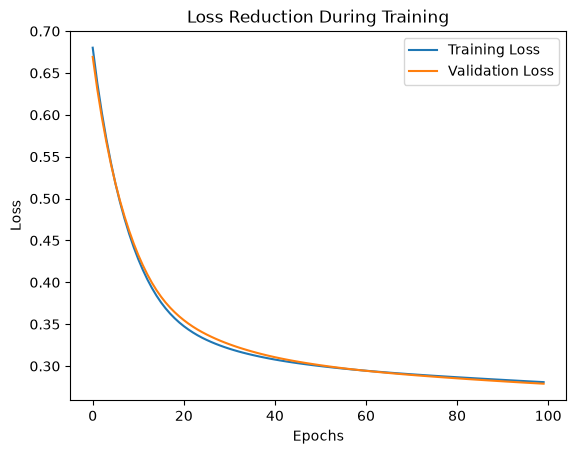

In [5]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Reduction During Training")

plt.legend()
plt.show()

In [6]:
learning_rates = [0.1, 0.01, 0.001]

for lr in learning_rates:

    model = keras.Sequential([
        layers.Input(shape=(2,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.SGD(
            learning_rate=lr
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=50,
        batch_size=32,
        verbose=0
    )

    print(
        f"Learning Rate: {lr}, "
        f"Final Loss: {history.history['loss'][-1]:.4f}"
    )

Learning Rate: 0.1, Final Loss: 0.2553
Learning Rate: 0.01, Final Loss: 0.3198
Learning Rate: 0.001, Final Loss: 0.5906
